In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.drop_dims(['time','latitude','longitude'])
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.drop_dims(['time','latitude','longitude'])
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.drop_dims(['time','latitude','longitude'])
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        #self.read_gosat()
        #self.read_insitu()
        #self.read_tccon()

In [3]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        print(dir)
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            if 'GCP' in labels[k]:
                s=labels[k][-1]
                data_sel=data[labels[k]].sel(ensemble_member=int(s))
                data_sel=data_sel.sel(latitude=lat_sel, longitude=lon_sel)
                name=''
                for r in data_sel.ensemble_member_name.values[0]:
                    name+=r
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=name)
            else:
                data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                                color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [4]:
def plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors,markers, title, start_date, end_date,spath,min_max=(-4e-7,4e-7)):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dataset in enumerate(datasets):
        print(dir)
        data[labels[k]]=dataset.sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'2x2 flux {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel, c=colors[k], marker=markers[k], markersize=ms, label=labels[k])      
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(min_max[0],min_max[1])
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [151]:
def plot_map(data,label,ax,cmap='RdBu_r',vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax,rasterized=True,add_colorbar=False)# cbar_kwargs={'location':'bottom','shrink':0.8, 'label':label})
    #plot.colorbar.ax.xaxis.label.set_size(16)
    #plot.colorbar.ax.tick_params(labelsize=16)
        
    '''  ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    '''
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
        
    ax.tick_params(labelsize=20)
    #ax.set_title('')
    return plot

In [ ]:
def plot_map_divided(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
    for i in range(n_regions[0]): #lat
        for j in range(n_regions[1]): #lon
            ax.hlines(regions_lat[i],regions_lon[j], regions_lon[j+1],color='b')
            ax.vlines(regions_lon[j],regions_lat[i],regions_lat[i+1],color='b')
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [7]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

print(regions_lat)
print(regions_lon)

[20, 34, 48]
[-126, -108, -90, -70]


In [8]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/model_comparison/2x3/'

In [9]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)
prior

<xarray.Dataset> Size: 6MB
Dimensions:         (time: 157, latitude: 22, longitude: 36)
Coordinates:
  * time            (time) datetime64[ns] 1kB 2019-12-30 ... 2022-12-26
  * latitude        (latitude) float64 176B 13.0 15.0 17.0 ... 51.0 53.0 55.0
  * longitude       (longitude) float64 288B -133.0 -131.0 ... -65.0 -63.0
Data variables:
    grid_cell_area  (time, latitude, longitude) float64 995kB 4.819e+10 ... 2...
    CO2_flux_nee    (time, latitude, longitude) float64 995kB 0.0 ... 1.254e-08
    CO2_flux_fire   (time, latitude, longitude) float64 995kB 0.0 ... 6.403e-43
    CO2_flux_oce    (time, latitude, longitude) float64 995kB 7.324e-10 ... -...
    CO2_flux_fos    (time, latitude, longitude) float64 995kB 1.085e-11 ... 1...
    total_flux      (time, latitude, longitude) float64 995kB 7.432e-10 ... 1...

In [87]:
GFED=xr.open_dataset('/work/bb1170/RUN/b383736/data/GFED/GFED5.1_co2_cut_2x2.nc')
GFED['CO2']=(GFED.CO2/prior.grid_cell_area).assign_attrs(units='kgCO2/(m^2 s)')
GFED=GFED.where((GFED.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(GFED.time<=pd.to_datetime(analysis_end_date)),drop=True)

GFED

<xarray.Dataset> Size: 996kB
Dimensions:    (time: 157, latitude: 22, longitude: 36)
Coordinates:
  * time       (time) datetime64[ns] 1kB 2019-12-30 2020-01-06 ... 2022-12-26
  * latitude   (latitude) float32 88B 13.0 15.0 17.0 19.0 ... 51.0 53.0 55.0
  * longitude  (longitude) float32 144B -133.0 -131.0 -129.0 ... -65.0 -63.0
    lat        (latitude) float32 88B ...
    lon        (longitude) float32 144B ...
Data variables:
    CO2        (time, latitude, longitude) float64 995kB 0.0 0.0 0.0 ... 0.0 0.0
Attributes:
    title:                GFED5.1 daily 2019-12
    subtitle:             Global Fire Emissions Database (GFED) extension ver...
    creation_date:        2025-08-30 22:52:44 UTC
    license:              Data in this file is licensed under a Creative Comm...
    region:               Global
    spatial_resolution:   0.25x0.25 degree
    temporal_resolution:  Day
    institution:          Wageningen Univerity & Research, and University of ...
    contact:              Guido van der Werf (guido.vanderwerf@wur.nl), Yang ...

In [88]:
GFED4=xr.open_dataset('/work/bb1170/RUN/b383736/data/GFED/GFED4_co2_cut_2x2.nc')
GFED4=GFED4.where((GFED4.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(GFED4.time<=pd.to_datetime(analysis_end_date)),drop=True)


In [89]:
path='inversions_new/TM5_3_years/'
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

inversion=data(path,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3)
inversion.read_data()
inversion.fluxes=inversion.fluxes.where((inversion.fluxes.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(inversion.fluxes.time<=pd.to_datetime(analysis_end_date)),drop=True)


assume fixed prior fossil fuel flux, fixed ocean flux, <br>
correct fire flux to GFED flux <br>
NEE flux=total-FF-GFED_fire-ocean

In [90]:
inversion.fluxes['CO2_flux_fos']=prior.CO2_flux_fos
inversion.fluxes['CO2_flux_oce']=prior.CO2_flux_oce
inversion.fluxes['CO2_flux_fire']=GFED.CO2
inversion.fluxes['CO2_flux_nee']=inversion.fluxes.TM5_posterior_flux - inversion.fluxes.CO2_flux_fos - GFED.CO2 - inversion.fluxes.CO2_flux_oce

inversion.fluxes

<xarray.Dataset> Size: 105MB
Dimensions:                    (time: 157, latitude: 22, longitude: 36,
                                meas_num: 38270)
Coordinates:
  * time                       (time) datetime64[ns] 1kB 2019-12-30 ... 2022-...
  * latitude                   (latitude) float32 88B 13.0 15.0 ... 53.0 55.0
  * longitude                  (longitude) float32 144B -133.0 -131.0 ... -63.0
  * meas_num                   (meas_num) int64 306kB 0 1 2 ... 38268 38269
    height                     float32 4B 30.0
    lat                        (latitude) float32 88B ...
    lon                        (longitude) float32 144B ...
Data variables:
    TM5_prior_flux             (time, latitude, longitude) float64 995kB 7.43...
    prior_uncertainty          (time, latitude, longitude) float64 995kB 6.24...
    TM5_posterior_flux         (time, latitude, longitude) float64 995kB 7.42...
    TM5_posterior_std          (time, latitude, longitude) float64 995kB 6.24...
    TM5_averaging_kernel_diag  (time, latitude, longitude) float64 995kB 1.34...
    meas                       (meas_num, time) float64 48MB -1.123 ... 5.879
    meas_cov                   (meas_num, time) float64 48MB 4.899 4.899 ... 3.0
    CO2_flux_fos               (time, latitude, longitude) float64 995kB 1.08...
    CO2_flux_oce               (time, latitude, longitude) float64 995kB 7.32...
    CO2_flux_fire              (time, latitude, longitude) float64 995kB 0.0 ...
    CO2_flux_nee               (time, latitude, longitude) float64 995kB -1.0...

In [91]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)


correct fire flux to GFED fire flux and adjust nee flux accordingly

In [92]:
TM54DVar_posterior_flux['CO2_flux_nee']=TM54DVar_posterior_flux['CO2_flux_nee']+TM54DVar_posterior_flux['CO2_flux_fire']-GFED.CO2
TM54DVar_posterior_flux['CO2_flux_fire']=GFED.CO2
TM54DVar_posterior_flux

<xarray.Dataset> Size: 6MB
Dimensions:         (time: 157, latitude: 22, longitude: 36)
Coordinates:
  * time            (time) datetime64[ns] 1kB 2019-12-30 ... 2022-12-26
  * latitude        (latitude) float32 88B 13.0 15.0 17.0 ... 51.0 53.0 55.0
  * longitude       (longitude) float32 144B -133.0 -131.0 ... -65.0 -63.0
    lat             (latitude) float32 88B ...
    lon             (longitude) float32 144B ...
Data variables:
    grid_cell_area  (time, latitude, longitude) float64 995kB 4.819e+10 ... 2...
    CO2_flux_nee    (time, latitude, longitude) float64 995kB 0.0 ... 1.327e-08
    CO2_flux_fire   (time, latitude, longitude) float64 995kB 0.0 0.0 ... 0.0
    CO2_flux_oce    (time, latitude, longitude) float64 995kB 5.369e-11 ... -...
    CO2_flux_fos    (time, latitude, longitude) float64 995kB 1.085e-11 ... 1...
    total_flux      (time, latitude, longitude) float64 995kB 6.453e-11 ... 1...

In [93]:
GCP=xr.open_dataset('/work/bb1170/RUN/b383736/data/GCP/GCP2024_inversions_2x2_version1_2_20241021_cut_weekly.nc')
GCP=GCP.where((GCP.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(GCP.time<=pd.to_datetime(analysis_end_date)),drop=True)
GCP['CO2_flux_nee']=GCP.land_flux_only_fossil_cement_adjusted-GFED.CO2
GCP['CO2_flux_fire']=GFED.CO2
GCP['CO2_flux_oce']=GCP.ocean_flux_NOT_adjusted
GCP['CO2_flux_fos']=GCP.fossil_fuel_emissions
gcp_names=[]
for i in GCP.ensemble_member:
    gcp_names.append(GCP.sel(ensemble_member=i).ensemble_member_name.values[0].sum())
print(gcp_names)
'''GCP
for ensemble in GCP.ensemble_member:
    letters=GCP.sel(ensemble_member=ensemble).ensemble_member_name.values[0]
    name=''
    for letter in letters:
        name=name+letter
'''
GCP

['CarboScope', 'CAMS', 'CTE', 'NISMON-CO2', 'CT-NOAA', 'CMS-Flux', 'CAMS-Satellite', 'GONGGA', 'COLA', 'GCASv2', 'UoE', 'IAPCAS', 'MIROC', 'NTFVAR']


<xarray.Dataset> Size: 131MB
Dimensions:                                (time: 157, ensemble_member: 14,
                                            nchars: 20, latitude: 22,
                                            longitude: 36)
Coordinates:
  * time                                   (time) datetime64[ns] 1kB 2019-12-...
  * latitude                               (latitude) float32 88B 13.0 ... 55.0
  * longitude                              (longitude) float32 144B -133.0 .....
    lat                                    (latitude) float32 88B ...
    lon                                    (longitude) float32 144B ...
Dimensions without coordinates: ensemble_member, nchars
Data variables: (12/15)
    ensemble_member_name                   (time, ensemble_member, nchars) object 352kB ...
    cell_area                              (time, latitude, longitude) float64 995kB ...
    land_flux_only_fossil_cement_adjusted  (time, ensemble_member, latitude, longitude) float64 14MB ...
    ocean_flux_NOT_adjusted                (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_land                        (time, ensemble_member, latitude, longitude) float64 14MB ...
    prior_flux_ocean                       (time, ensemble_member, latitude, longitude) float64 14MB ...
    ...                                     ...
    river_adjustment_ocean                 (time, latitude, longitude) float64 995kB ...
    total_flux                             (time, ensemble_member, latitude, longitude) float64 14MB ...
    CO2_flux_nee                           (time, ensemble_member, latitude, longitude) float64 14MB ...
    CO2_flux_fire                          (time, latitude, longitude) float64 995kB ...
    CO2_flux_oce                           (time, ensemble_member, latitude, longitude) float64 14MB ...
    CO2_flux_fos                           (time, ensemble_member, latitude, longitude) float64 14MB ...
Attributes: (12/18)
    contact:                    Ingrid Luijkx, Wageningen University, ingrid....
    contact_all:                Comma separated email addresses: christian.ro...
    Conventions:                CF-1.8
    creation_date:              2024-10-21
    creator:                    Ingrid Luijkx, Wageningen University, orcid:0...
    crs:                        spherical earth with radius of 6371 km
    ...                         ...
    product_version:            1.0
    project:                    Global Carbon Project, GCB2024
    references:                 Please inform the inverse modelling group whe...
    source:                     Below is a list of the versions of each syste...
    summary:                    In this file, we include the data from the GC...
    title:                      Global CO2 gridded flux fields from 14 atmosp...

# fossil fuel

In [25]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(24,12))
fig.suptitle('Fossil Fuel Emissions',fontsize=22)
min,max=-0.001,0.05
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_fos*1e6, c=default_colors[0], marker='o', markersize=2, label=f'our posterior/ TM5-4DVar')

        temp3=GCP.where(((GCP.latitude>= regions_lat[-i-2]) &(GCP.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        axs[i,j].plot(temp3.time, temp3.sel(ensemble_member=0).fossil_fuel_emissions*1e6, c=default_colors[1], marker='o', markersize=2, label='GCP models')
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(0,0.05)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_different_models_FF.pdf',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

/tmp/ipykernel_615234/1850919216.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/1850919216.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/1850919216.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


In [ ]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.CO2_flux_fos,TM54DVar_posterior_flux.CO2_flux_fos,inversion.fluxes.CO2_flux_fos]
labels=['prior','TM5-4DVar', 'our posterior' ]

for k in [0,1,2]:
    datasets.append(GCP.sel(ensemble_member=k).fossil_fuel_emissions)
    labels.append(gcp_names[k])
        
colors=['black','grey',default_colors[0],default_colors[1],default_colors[2],default_colors[3]]
marker=['x','x','o','x','x','x']

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/different_mfig.colorbar(plot, location='bottom', shrink=0.85)odels_FF'+'2x2.png',min_max=(-0.005*1e-6,0.005*1e-6))


['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
['x', 'x', 'o', 'x', 'x', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
saved to: figures_2/3years/model_comparison//different_models_FF2x2.png


In [52]:
temp=(prior.CO2_flux_fos-GCP.sel(ensemble_member=0).fossil_fuel_emissions)*1e6
temp=temp.where((temp.latitude>=analy_region_lat[0])&(temp.latitude<=analy_region_lat[1])&(temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]), drop=True)
print('absolute difference')
print('max: '+str(np.max(temp.values)))
print('min: '+ str(np.min(temp.values)))
print('mean: '+ str(np.mean(temp.values)))
print('std: '+ str(np.std(temp.values)))


absolute difference
max: 0.05381614850927408
min: -0.10802188679856642
mean: 4.185335351842113e-05
std: 0.011148200783444943


In [147]:
inversion.fluxes=inversion.fluxes.drop_vars('height')

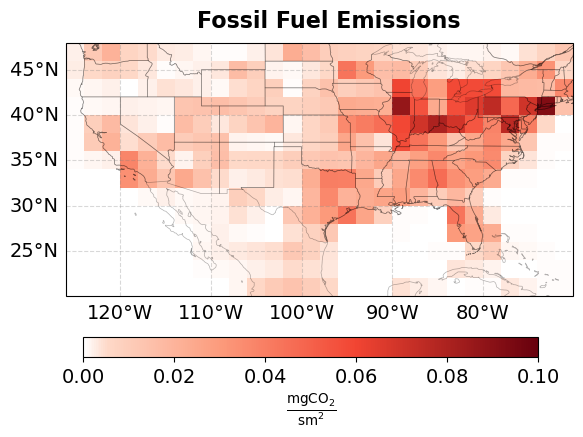

In [175]:
fig,axs=plt.subplots(1,1,figsize=(7,4), subplot_kw={'projection': ccrs.PlateCarree()})
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

fig.suptitle(f"Fossil Fuel Emissions", fontsize=16, fontweight='bold')
temp=inversion.fluxes.CO2_flux_fos.mean('time')*1e6
plot=plot_map(temp,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,cmap=cmap,vmin=0.00,vmax=0.1)
fig.subplots_adjust(right=0.85, top=1.05)
cbar_ax = fig.add_axes([0.15, 0.11, 0.65, 0.05])   # (left, bottom, width, height)
cbar = fig.colorbar(plot, cax=cbar_ax,orientation='horizontal')
cbar.set_label('$\\mathrm{\\frac{mgCO_2}{s m^2}}$', fontsize=14)
cbar.ax.tick_params(labelsize=14)
plt.savefig(f'{savefig}/map_FF.pdf',bbox_inches='tight')
plt.show()

# Fire

In [24]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(24,12))
fig.suptitle('Fire Flux',fontsize=22)
min,max=-0.001,0.008
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        s=3
        temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_fire*1e6, c='black', marker='o', markersize=2, label=f"our/ TM5-4DVar's prior")

        temp=GFED.where(((GFED.latitude>= regions_lat[-i-2]) &(GFED.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2*1e6, c=default_colors[s], marker='o', markersize=2, label=f'GFED5')
        s=1
        temp3=GFED4.where(((GFED4.latitude>= regions_lat[-i-2]) &(GFED4.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        axs[i,j].plot(temp3.time, temp3.CO2*1e6, c=default_colors[s], marker='o', markersize=2, label='GFED4')
        
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(0,0.07)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_different_models_fire.pdf',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

/tmp/ipykernel_615234/1430253402.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/1430253402.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/1430253402.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


In [56]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.CO2_flux_fire,TM54DVar_posterior_flux.CO2_flux_fire,inversion.fluxes.CO2_flux_fire]
labels=['prior','TM5-4DVar','our posterior' ]

'''for k in [0,1,2]:
    datasets.append(GCP.sel(ensemble_member=k).fossil_fuel_emissions)
    labels.append(gcp_names[k])'''
        
colors=['black','grey',default_colors[0],default_colors[1],default_colors[2],default_colors[3]]
marker=['x','x','o','x','x','x']

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/different_models_fire_'+'2x2.png',min_max=(-0.005*1e-6,0.005*1e-6))


['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
['x', 'x', 'o', 'x', 'x', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>


In [53]:
temp=(GFED.CO2-GFED4.CO2)*1e6
temp=temp.where((temp.latitude>=analy_region_lat[0])&(temp.latitude<=analy_region_lat[1])&(temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]), drop=True)
print('absolute difference')
print('max: '+str(np.max(temp.values)))
print('min: '+ str(np.min(temp.values)))
print('mean: '+ str(np.mean(temp.values)))
print('std: '+ str(np.std(temp.values)))

absolute difference
max: 7.254401241207429
min: -0.6435771013841547
mean: 0.0020288255032635165
std: 0.03940936222261715


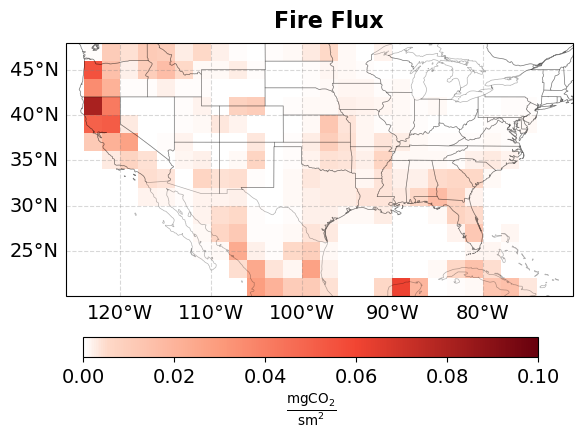

In [174]:
fig,axs=plt.subplots(1,1,figsize=(7,4), subplot_kw={'projection': ccrs.PlateCarree()})
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

fig.suptitle(f"Fire Flux", fontsize=16, fontweight='bold')
temp=inversion.fluxes.CO2_flux_fire.mean('time')*1e6
plot=plot_map(temp,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,cmap=cmap,vmin=0.00,vmax=0.1)
fig.subplots_adjust(right=0.85, top=1.05)
cbar_ax = fig.add_axes([0.15, 0.11, 0.65, 0.05])   # (left, bottom, width, height)
cbar = fig.colorbar(plot, cax=cbar_ax,orientation='horizontal')
cbar.set_label('$\\mathrm{\\frac{mgCO_2}{s m^2}}$', fontsize=14)
cbar.ax.tick_params(labelsize=14)
plt.savefig(f'{savefig}/map_fire.pdf',bbox_inches='tight')
plt.show()

# Ocean

/tmp/ipykernel_615234/3723003111.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/3723003111.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/3723003111.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


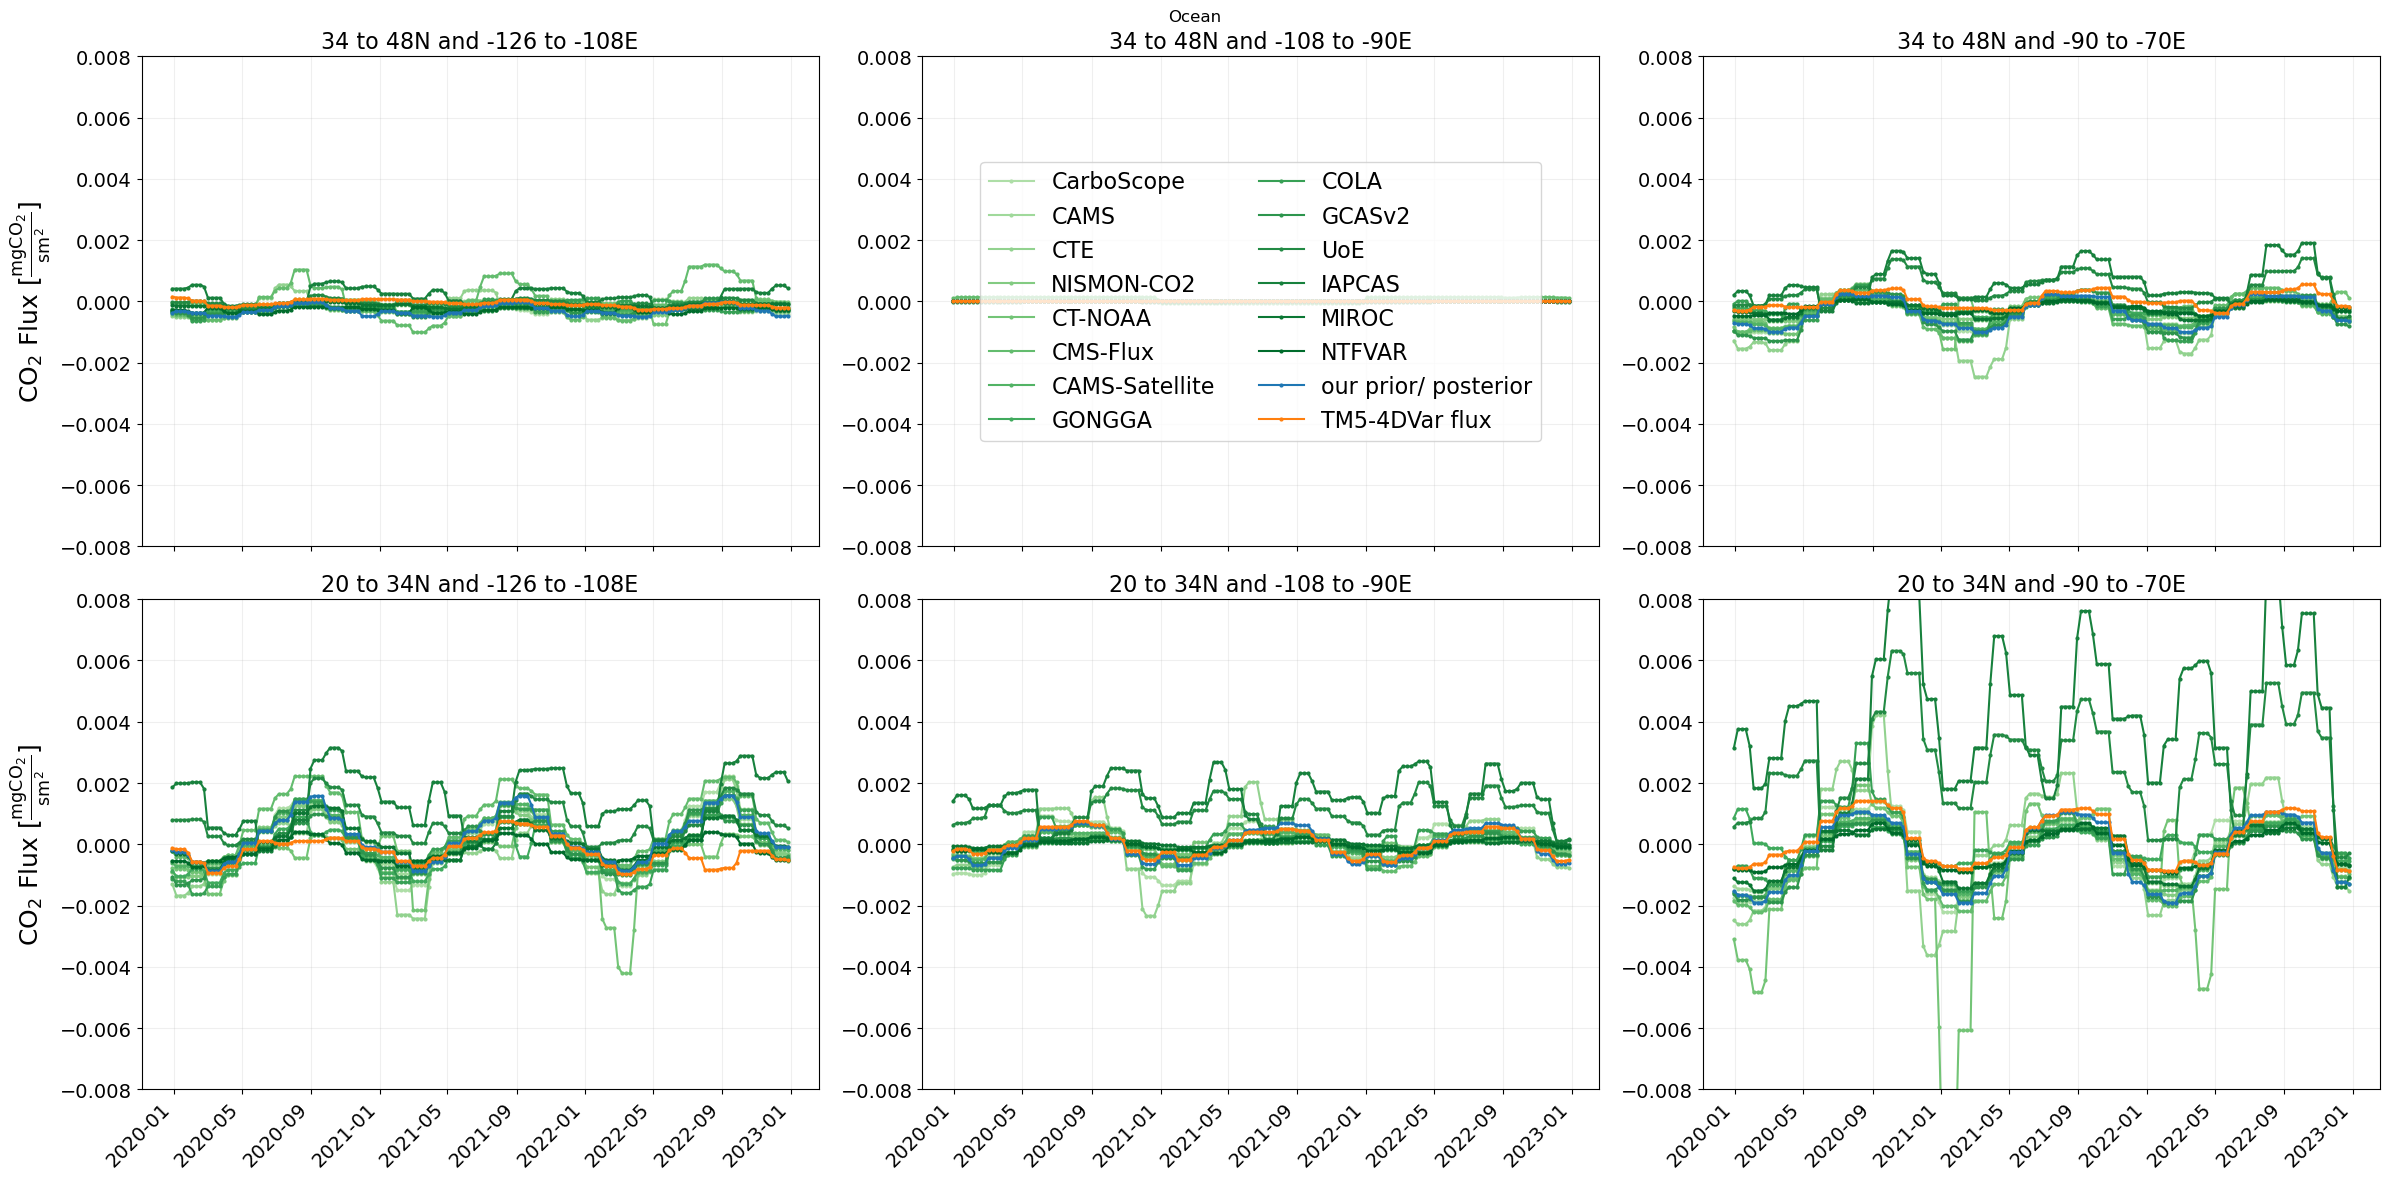

In [51]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(24,12))
fig.suptitle('Ocean')
min,max=-0.008,0.008
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
       
        for ensemble in (GCP.ensemble_member.values):
            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+8)/(len(GCP.ensemble_member)+10)
            axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])
        s=0

        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, c=default_colors[s], marker='o', markersize=2, label=f'our prior/ posterior')
        s+=1
        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        axs[i,j].plot(temp3.time, temp3.CO2_flux_oce*1e6, c=default_colors[s], marker='o', markersize=2, label='TM5-4DVar')
        
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        if i==0 and j==1:
            axs[i,j].legend(ncols=2,fontsize=16, loc='center')
        axs[i,j].set_ylim(min,max)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_different_models_ocean.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
plt.close()

/tmp/ipykernel_615234/672503295.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/672503295.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_615234/672503295.py:45: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


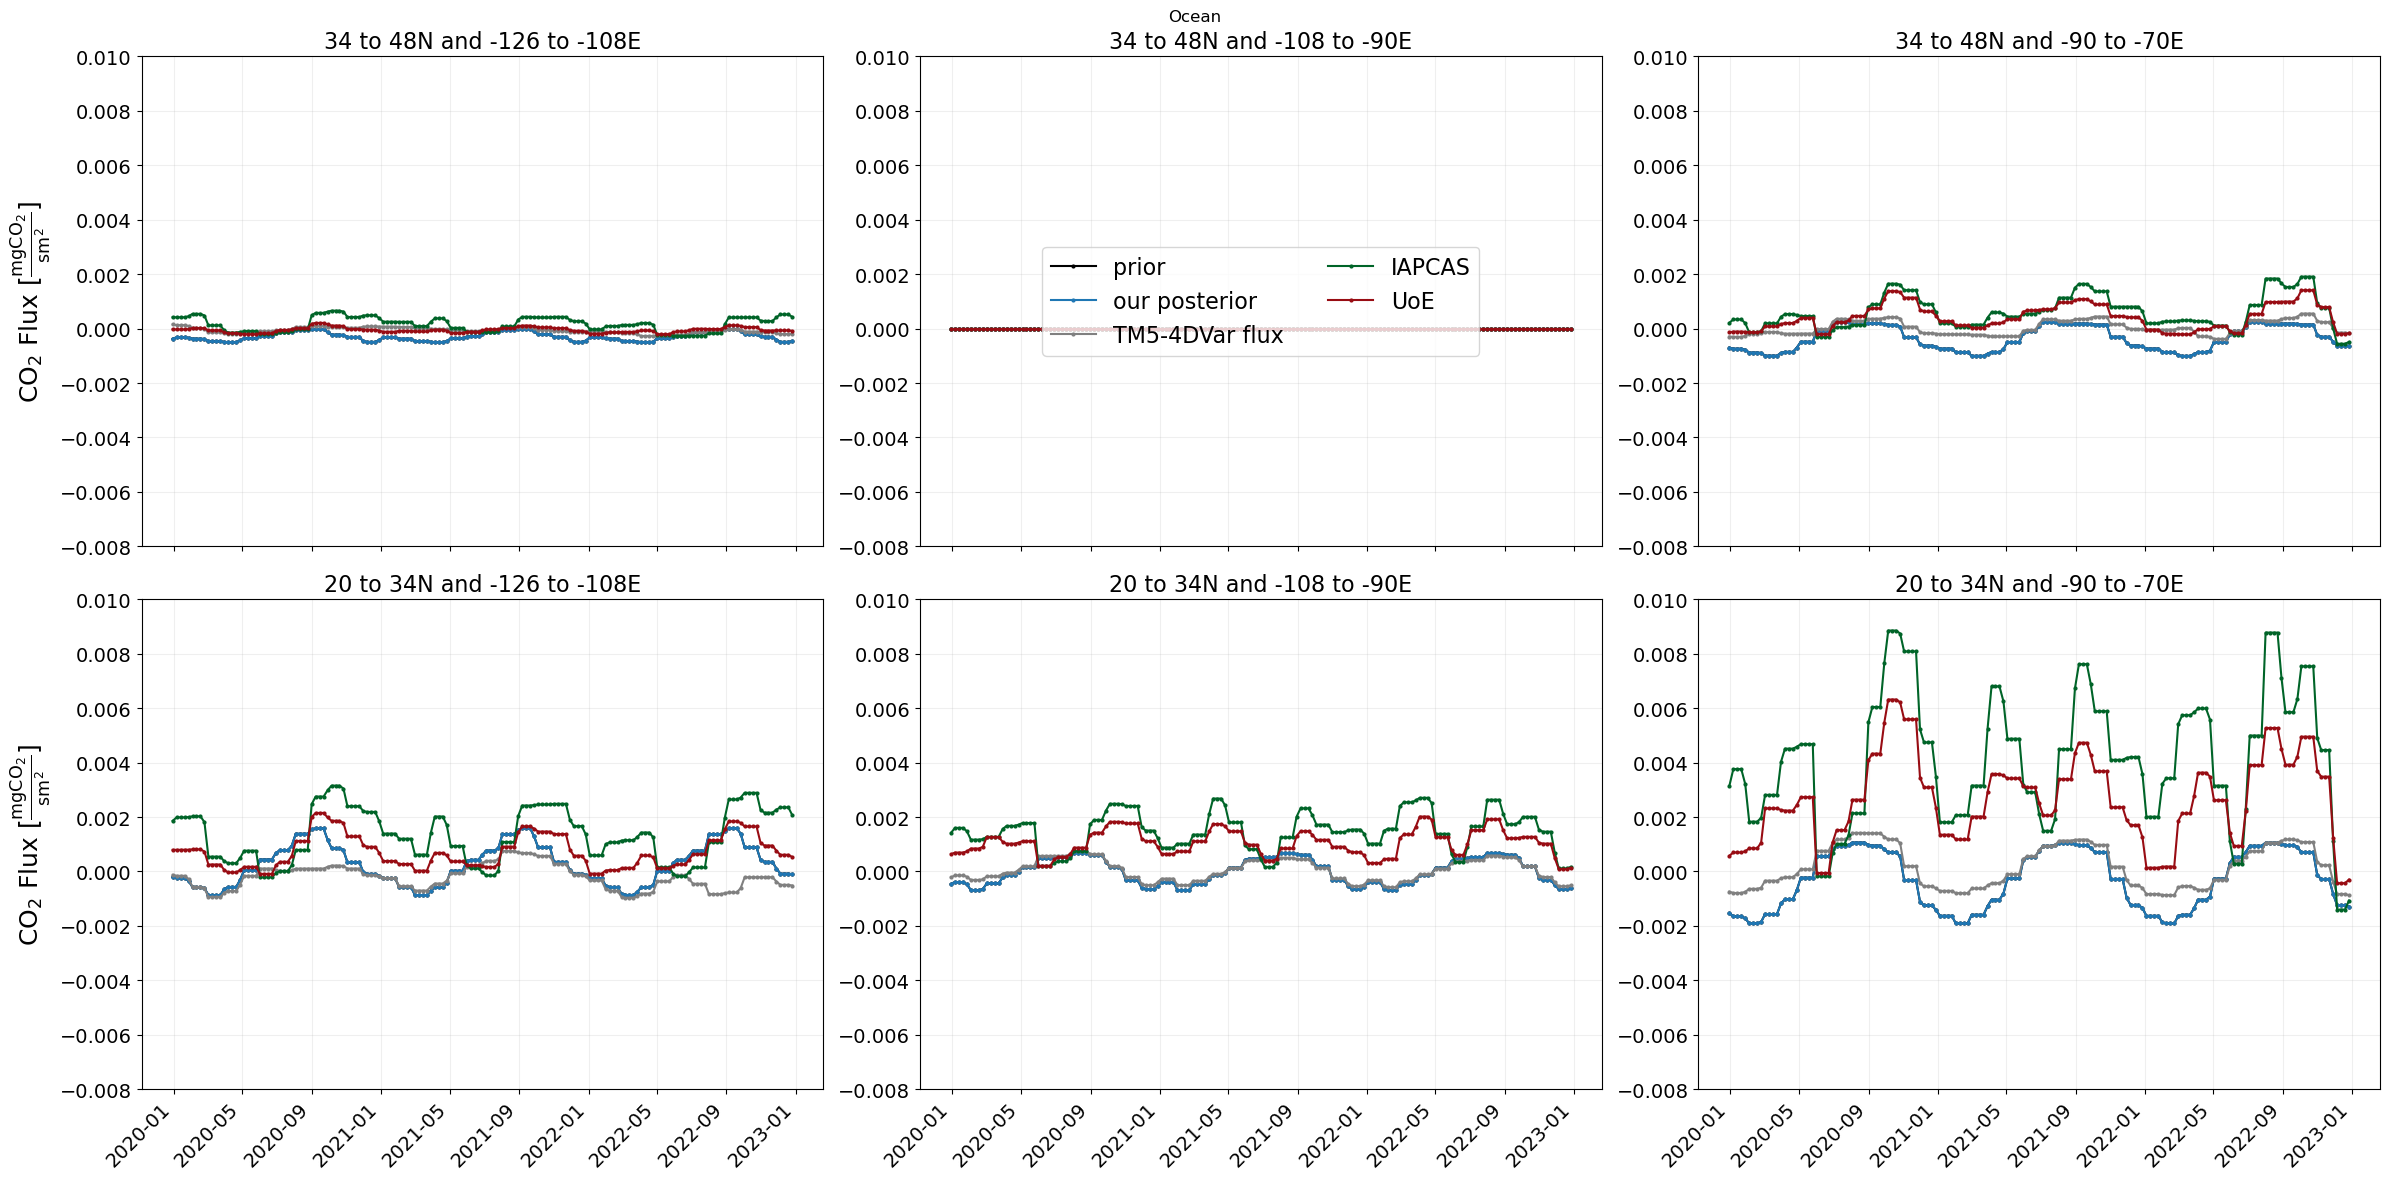

In [47]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(24,12))
fig.suptitle('Ocean')
min,max=-0.008,0.01
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        s=0
        temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, c='black', marker='o', markersize=2, label=f'prior')

        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, c=default_colors[s], marker='o', markersize=2, label=f'our posterior')
        s+=1
        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        axs[i,j].plot(temp3.time, temp3.CO2_flux_oce*1e6, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')
        
        for ensemble in ([11]):
            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            #color=(ensemble+8)/(len(GCP.ensemble_member)+10)
            axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, marker='o', color= plt.cm.Greens(0.9), markersize=2,label=gcp_names[ensemble])
        for ensemble in ([10]):
                temp=GCP.sel(ensemble_member=ensemble)
                temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
                temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
                temp=temp.mean(['latitude','longitude'])
                #color=(ensemble+8)/(len(GCP.ensemble_member)+10)
                axs[i,j].plot(temp.time, temp.CO2_flux_oce*1e6, marker='o', color= plt.cm.Reds(0.9), markersize=2,label=gcp_names[ensemble])
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        if i==0 and j==1:
            axs[i,j].legend(ncols=2,fontsize=16, loc='center')
        axs[i,j].set_ylim(min,max)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.tight_layout()
#plt.savefig(f'{savefig}/regional_fluxes_different_models_ocean.png',bbox_inches='tight')#,transparent=True)
plt.show()
plt.close()

In [58]:
temp=(GCP.ocean_flux_NOT_adjusted)*1e6
temp=temp.where((temp.latitude>=analy_region_lat[0])&(temp.latitude<=analy_region_lat[1])&(temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]), drop=True)
print(' difference')
print('max: '+str(np.max(temp.values)))
print('min: '+ str(np.min(temp.values)))
print('mean: '+ str(np.mean(temp.values)))
print('std: '+ str((temp.std('ensemble_member').mean(['latitude','longitude','time']))))

 difference
max: 0.012305744629501047
min: -0.04907264160559785
mean: 4.000610049684612e-05
std: <xarray.DataArray 'ocean_flux_NOT_adjusted' ()> Size: 8B
array(0.00066501)


In [55]:
temp=(prior.CO2_flux_oce-GCP.sel(ensemble_member=0).ocean_flux_NOT_adjusted)*1e6
temp=temp.where((temp.latitude>=analy_region_lat[0])&(temp.latitude<=analy_region_lat[1])&(temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]), drop=True)
print('absolute difference')
print('max: '+str(np.max(temp.values)))
print('min: '+ str(np.min(temp.values)))
print('mean: '+ str(np.mean(temp.values)))
print('std: '+ str(np.std(temp.values)))


absolute difference
max: 0.005640842244564311
min: -0.007459384243629086
mean: -1.3973160796711005e-05
std: 0.0007723497856231296


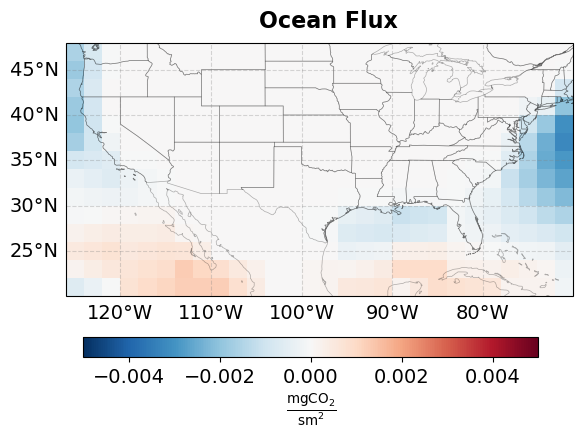

In [173]:
fig,axs=plt.subplots(1,1,figsize=(7,4), subplot_kw={'projection': ccrs.PlateCarree()})
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

fig.suptitle(f"Ocean Flux", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.85)
temp=inversion.fluxes.CO2_flux_oce.mean('time')*1e6
plot=plot_map(temp,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,vmin=-0.005,vmax=0.005)
fig.subplots_adjust(right=0.85, top=1.05)
cbar_ax = fig.add_axes([0.15, 0.11, 0.65, 0.05])   # (left, bottom, width, height)
cbar = fig.colorbar(plot, cax=cbar_ax,orientation='horizontal')
cbar.set_label('$\\mathrm{\\frac{mgCO_2}{s m^2}}$', fontsize=14)
cbar.ax.tick_params(labelsize=14)
plt.savefig(f'{savefig}/map_ocean.pdf',bbox_inches='tight')
plt.show()

In [63]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc'
TM5_posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
our_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc'
GCP_path='/work/bb1170/RUN/b383736/data/GCP/GCP2024_inversions_2x2_version1_2_20241021_cut_weekly.nc'
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.CO2_flux_oce,TM54DVar_posterior_flux.CO2_flux_oce]
labels=['prior','TM5-4DVar' ]

for k in [0,1,2]:
    datasets.append(GCP.sel(ensemble_member=k).CO2_flux_oce)
    labels.append(gcp_names[k])
        
colors=['black','grey',default_colors[0],default_colors[1],default_colors[2],default_colors[3]]
marker=['x','x','o','x','x','x']

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/different_models_ocean'+'2x2.png',min_max=(-0.005*1e-6,0.005*1e-6))


['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
['x', 'x', 'o', 'x', 'x', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
saved to: figures_2/3years/model_comparison//different_models_ocean2x2.png


# NEE

In [62]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[3,4] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

print(regions_lat)
print(regions_lon)

[20, 30, 40, 48]
[-126, -112, -98, -84, -70]


In [63]:
period='20191001-20230331'
analysis_start_date, analysis_end_date =dt.date(2020,1,1), dt.date(2022,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/3years/model_comparison/'

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4113502/1133910376.py:30: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


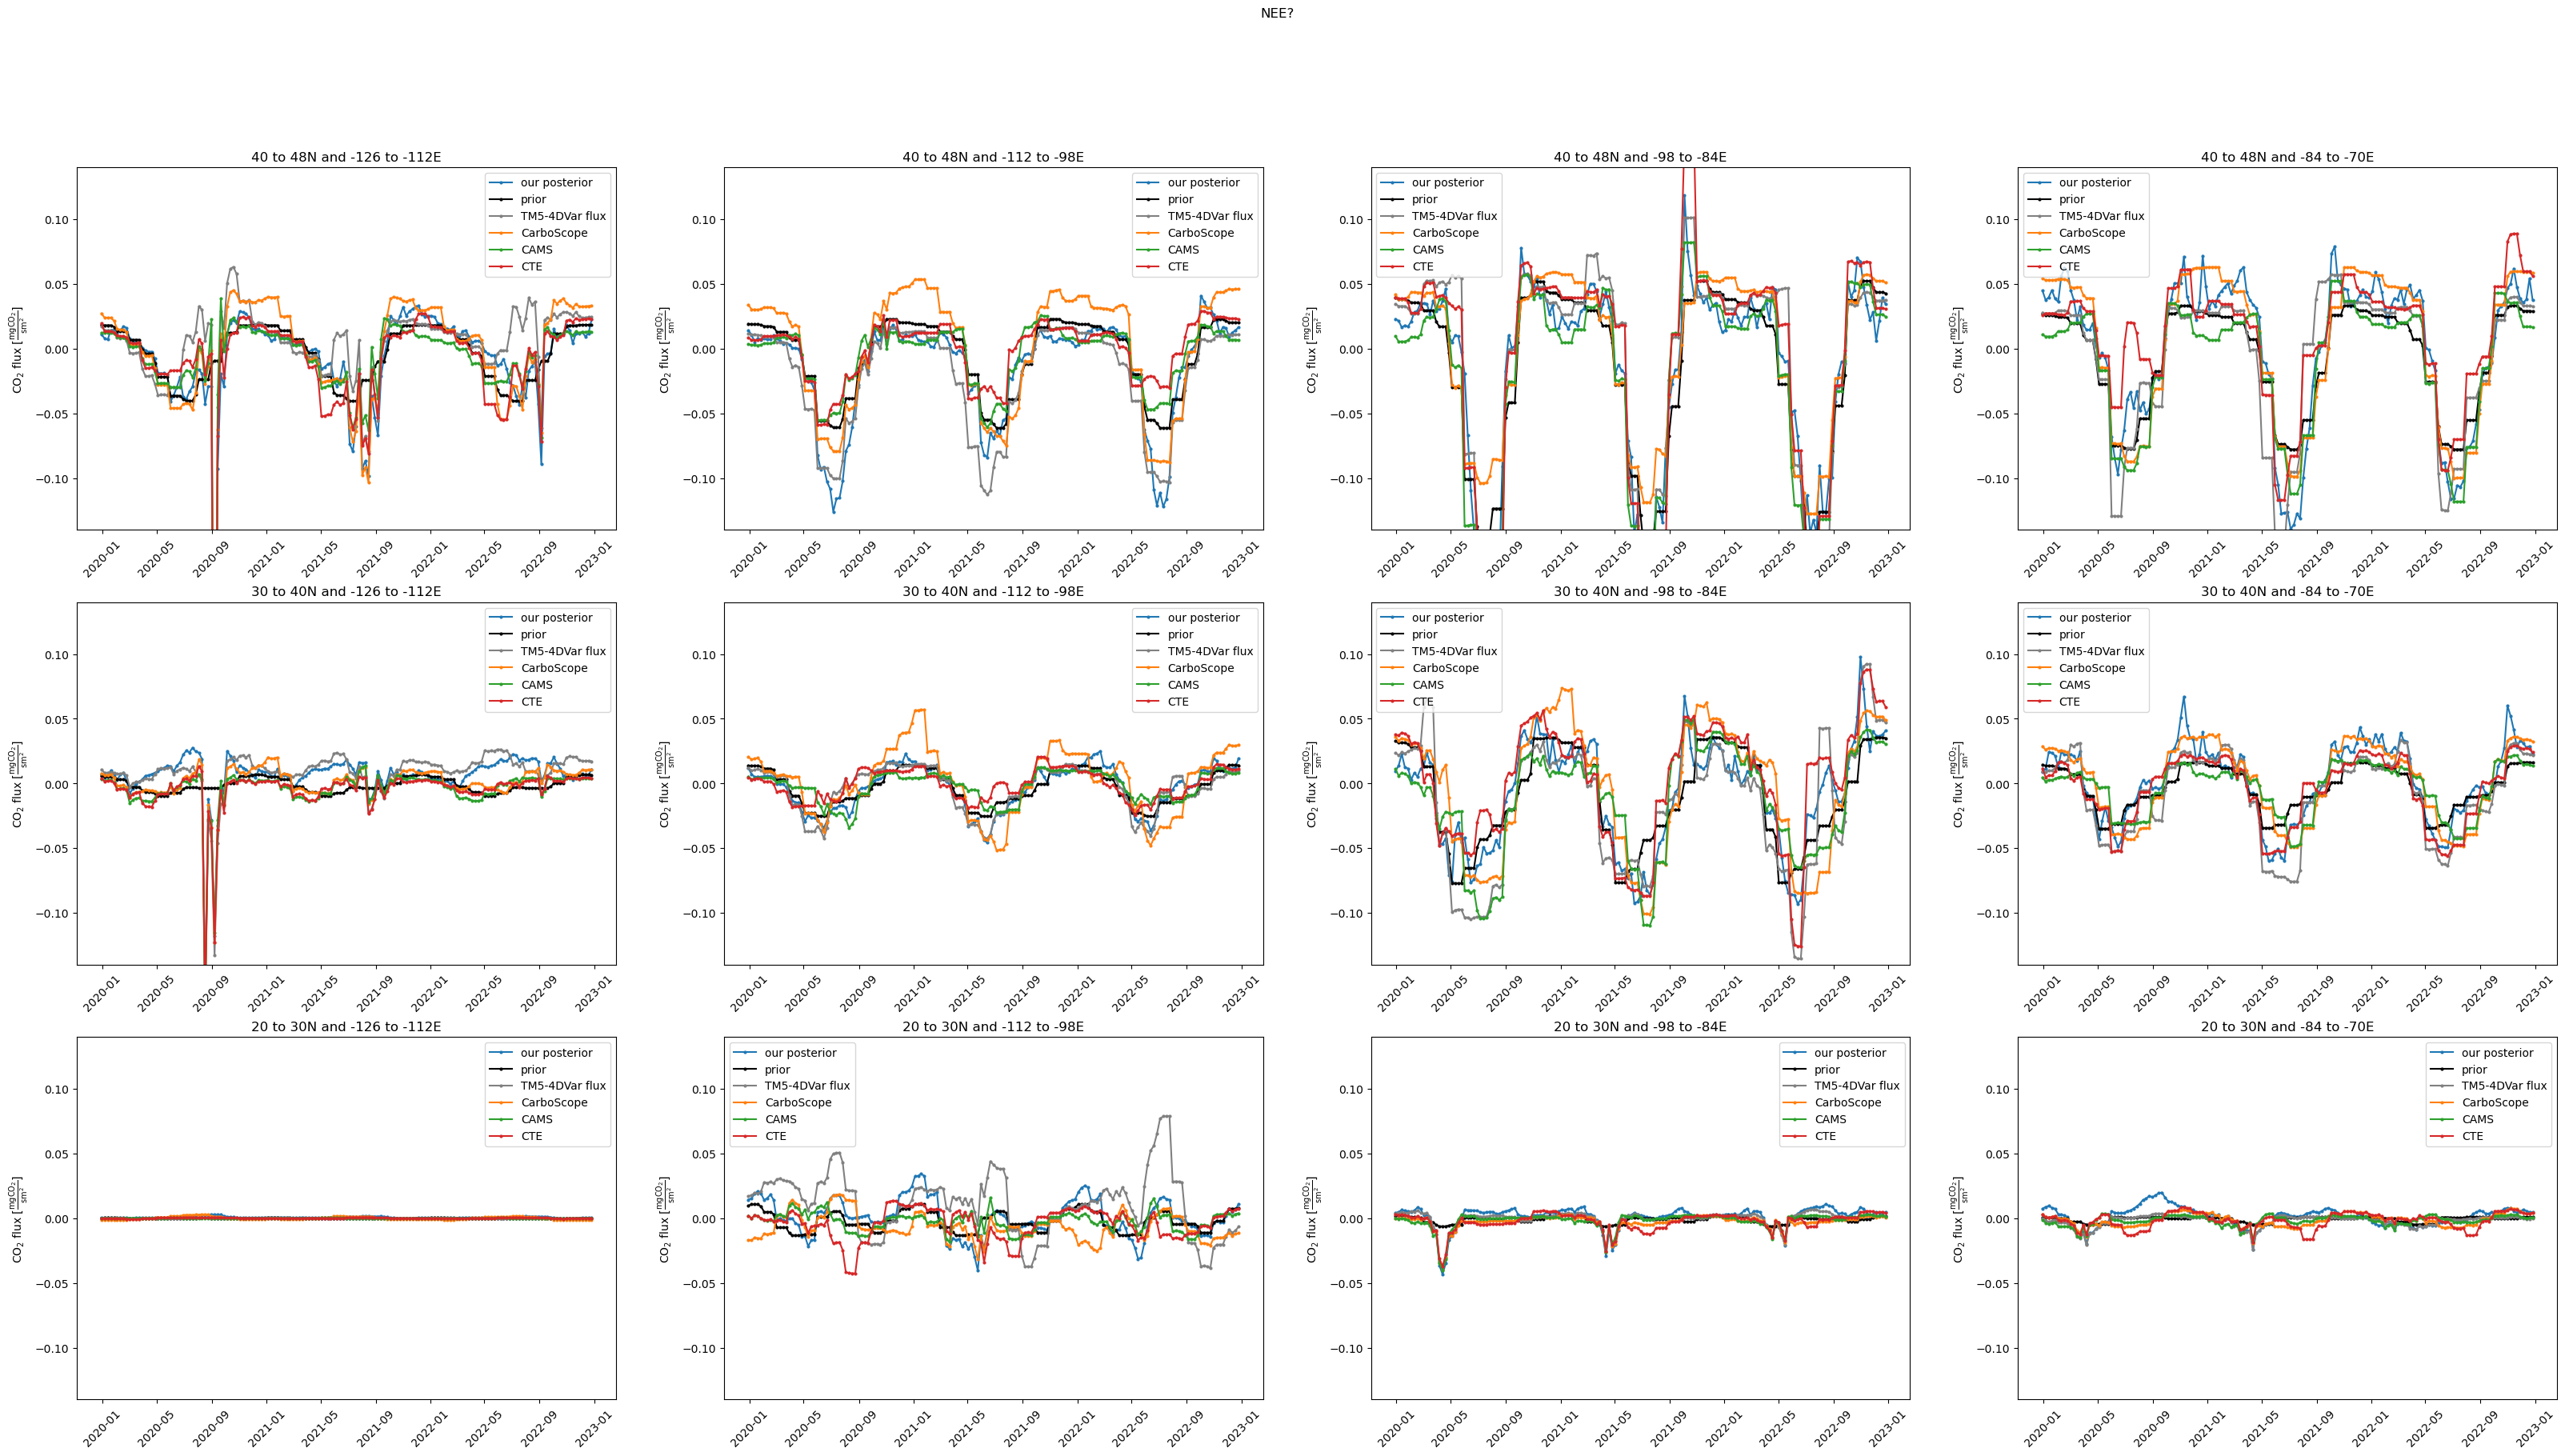

In [23]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
fig.suptitle('NEE?')
min,max=-0.14,0.14
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        s=0
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, c=default_colors[s], marker='o', markersize=2, label=f'our posterior')
        s+=1
        temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, c='black', marker='o', markersize=2, label=f'prior')

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        axs[i,j].plot(temp3.time, temp3.CO2_flux_nee*1e6, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')
        
        temp3=GCP.where(((GCP.latitude>= regions_lat[-i-2]) &(GCP.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        for k in [0,1,2]:
            axs[i,j].plot(temp3.time, temp3.sel(ensemble_member=k).CO2_flux_nee*1e6, c=default_colors[s], marker='o', markersize=2, label=gcp_names[k])
            s+=1
        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(min,max)
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
#plt.savefig(f'{savefig}/regional_fluxes_different_models.png',bbox_inches='tight')#,transparent=True)
plt.show()
plt.close()

In [18]:
temp=(prior.CO2_flux_oce-GCP.sel(ensemble_member=0).CO2_flux_oce)*1e6
print('absolute difference')
print('max: '+str(np.max(temp.values)))
print('min: '+ str(np.min(temp.values)))
print('mean: '+ str(np.mean(temp.values)))
print('std: '+ str(np.std(temp.values)))


absolute difference
max: 0.013248009269284952
min: -0.024175205581971667
mean: -7.029921214822713e-05
std: 0.001164367053981123


In [27]:

default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
datasets=[prior.CO2_flux_nee,TM54DVar_posterior_flux.CO2_flux_nee,inversion.fluxes.CO2_flux_nee]
labels=['prior','TM5-4DVar' ,'our posterior']

for k in [0,1,2]:
    datasets.append(GCP.sel(ensemble_member=k).CO2_flux_nee)
    labels.append(gcp_names[k])
        
colors=['black','grey',default_colors[0],default_colors[1],default_colors[2],default_colors[3]]
marker=['x','x','o','x','x','x']

print(colors)
print(marker)
plot_inner_2x2_region_fluxes_from_datasets(datasets,labels, colors, marker,'different models', analysis_start_date, analysis_end_date,savefig+'/different_models_nee'+'2x2.png',min_max=(-0.13*1e-6,0.13*1e-6))


['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
['x', 'x', 'o', 'x', 'x', 'x']
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>
<built-in function dir>


saved to: figures_2/3years/model_comparison//different_models_nee2x2.png


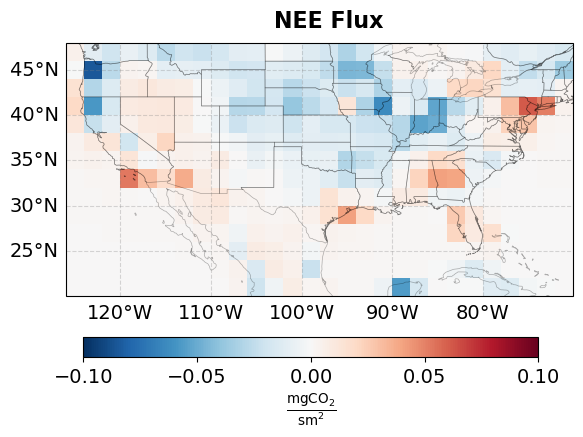

In [172]:
fig,axs=plt.subplots(1,1,figsize=(7,4), subplot_kw={'projection': ccrs.PlateCarree()})
cmap = LinearSegmentedColormap.from_list( 'white_red',[(0.00, 'white'), (0.05, plt.cm.Reds(0.15)), (0.30, plt.cm.Reds(0.35)), (0.60, plt.cm.Reds(0.60)), (1.00, plt.cm.Reds(1.00)) ])

fig.suptitle(f"NEE Flux", fontsize=16, fontweight='bold')
fig.subplots_adjust(right=0.7)
temp=inversion.fluxes.CO2_flux_nee.mean('time')*1e6
plot=plot_map(temp,'$\\mathrm{\\frac{mgCO_2}{s m^2}}$',axs,vmin=-0.1,vmax=0.1)
fig.subplots_adjust(right=0.85, top=1.05)
cbar_ax = fig.add_axes([0.15, 0.11, 0.65, 0.05])   # (left, bottom, width, height)
cbar = fig.colorbar(plot, cax=cbar_ax,orientation='horizontal')
cbar.set_label('$\\mathrm{\\frac{mgCO_2}{s m^2}}$', fontsize=14)
cbar.ax.tick_params(labelsize=14)
plt.savefig(f'{savefig}/map_nee.pdf',bbox_inches='tight')
plt.show()

# flux components in one plot

## our inversion

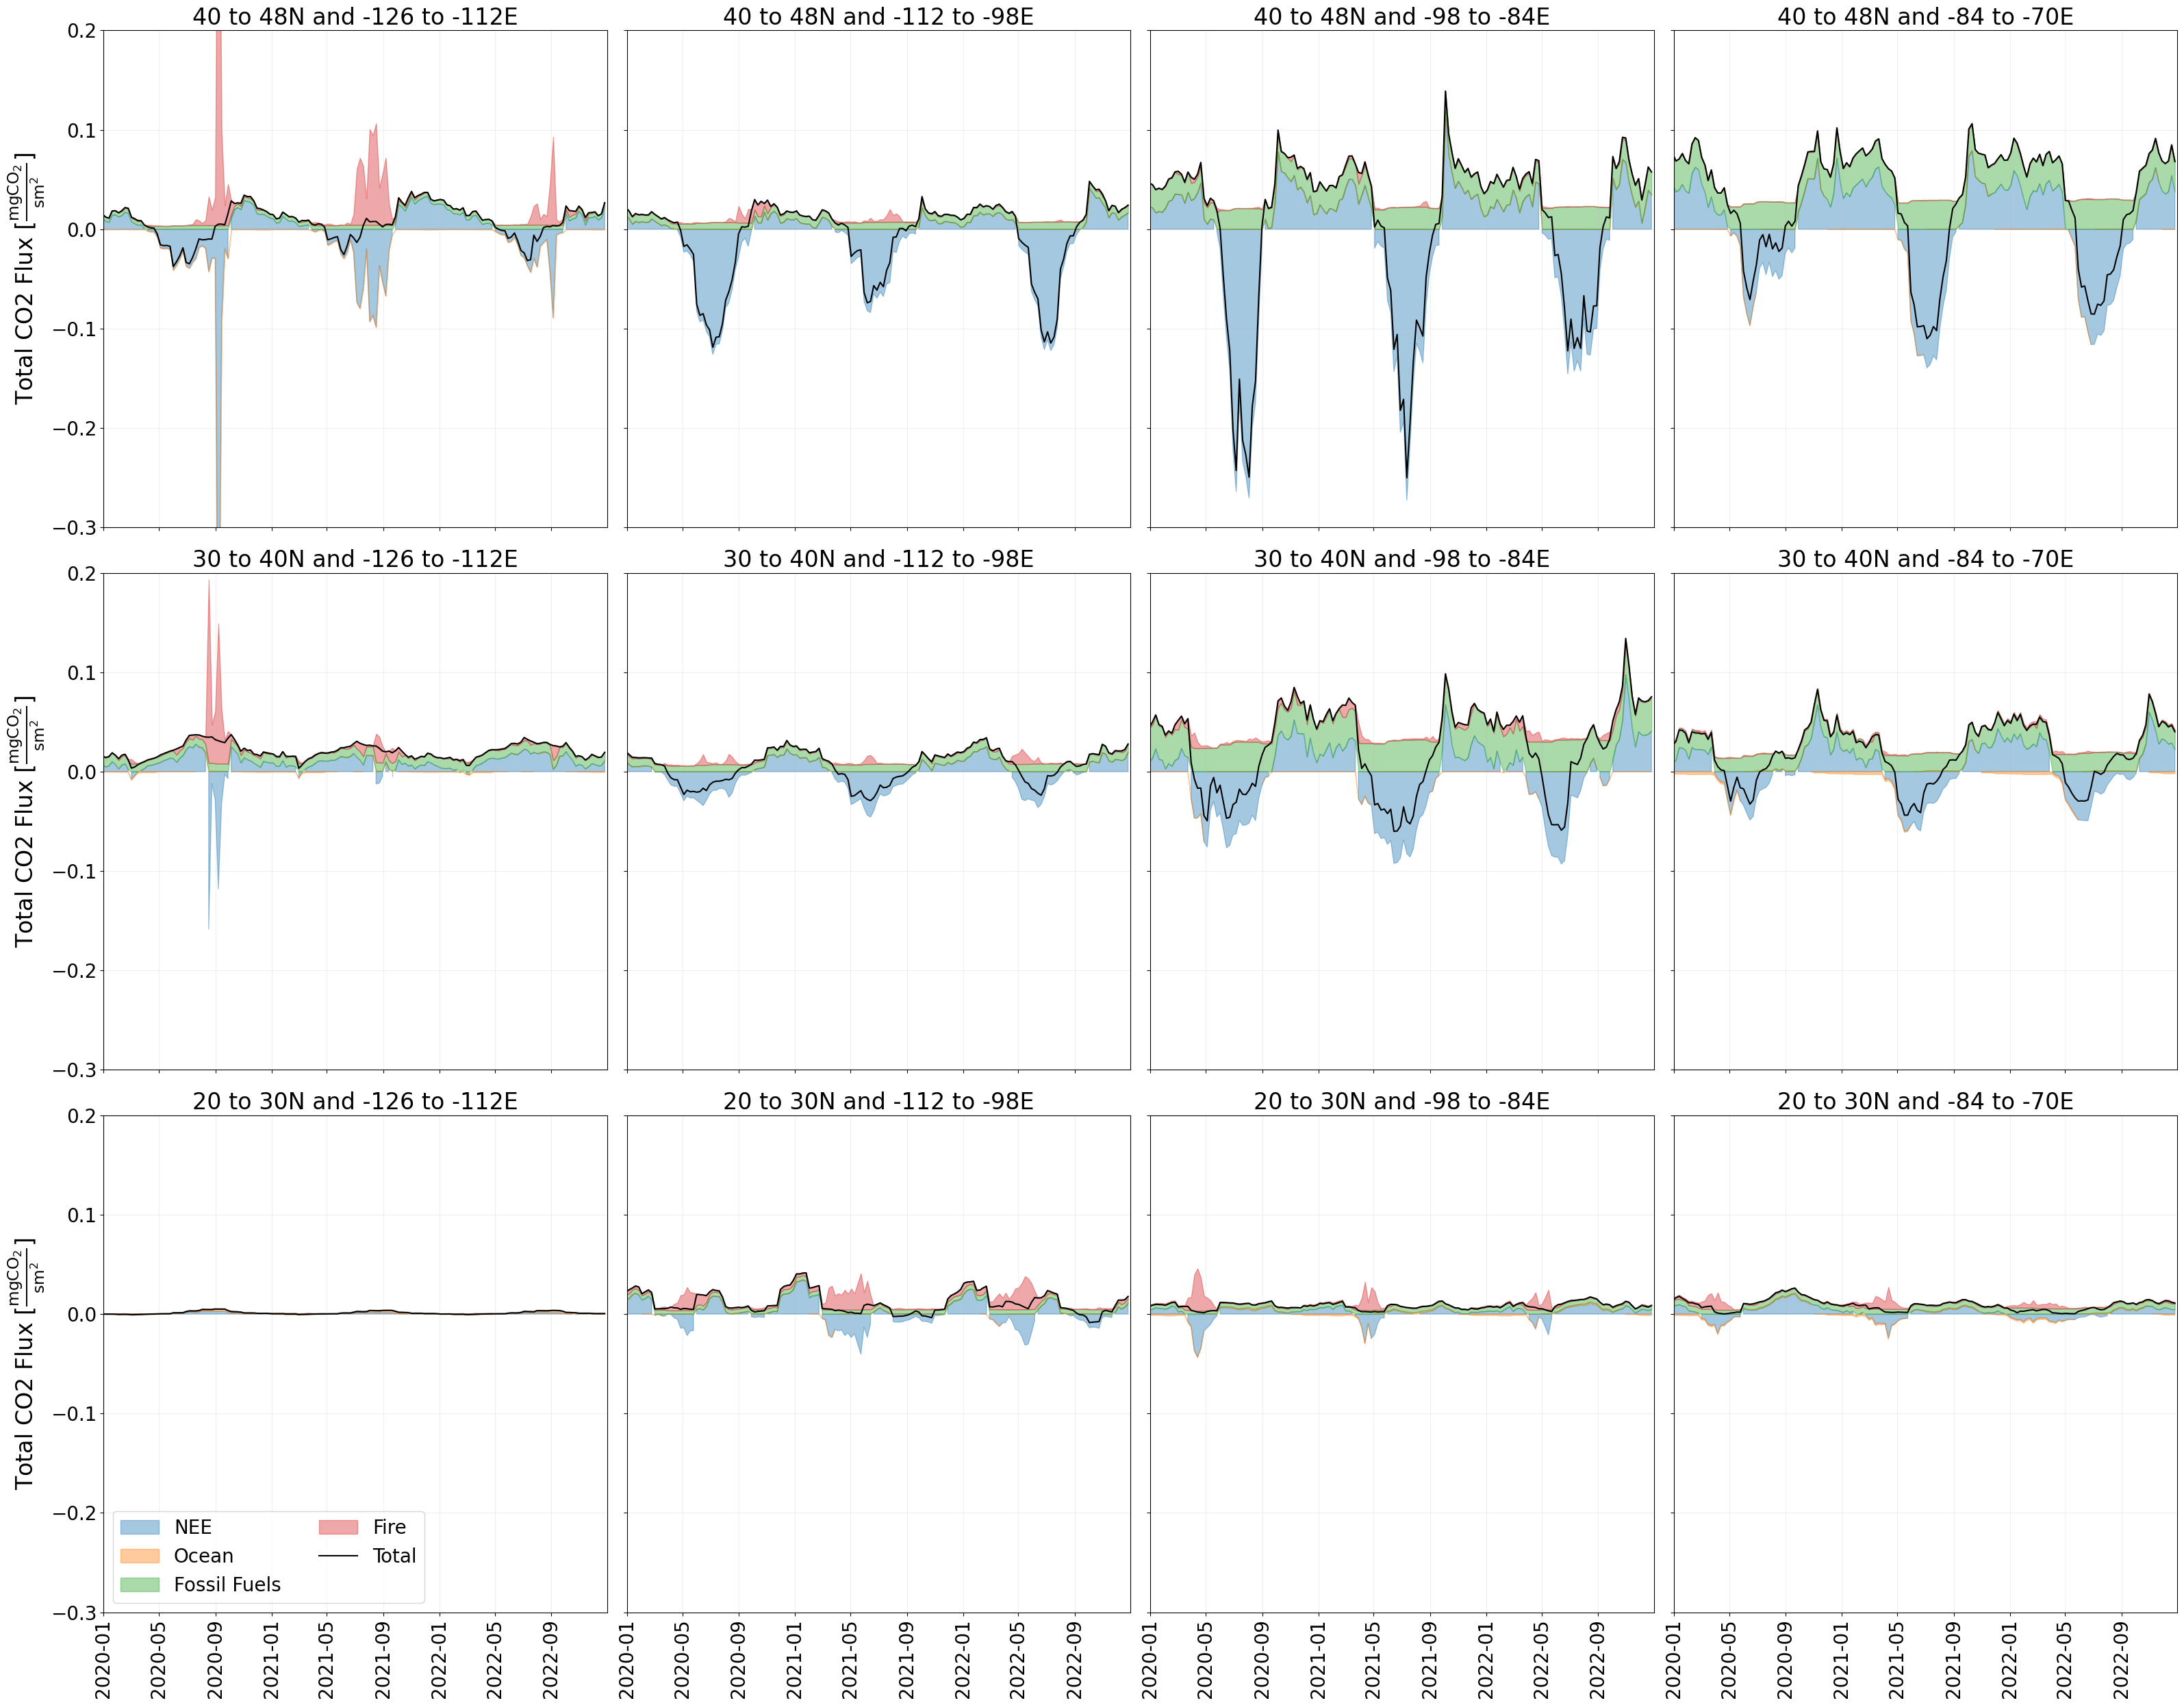

In [178]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(32,25))
min,max=-0.3,0.2
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
inv=inversion.fluxes
inv['all_max']=np.maximum(inv.TM5_prior_flux, 0)
inv['all_max']=np.minimum(inv.all_max, 0)
inv['all_min']=inv.all_max
fluxes=['CO2_flux_nee','CO2_flux_oce','CO2_flux_fos','CO2_flux_fire']
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        s=0
        temp=inv.where(((inv.latitude>= regions_lat[-i-2]) &(inv.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        labels=['NEE', 'Ocean', 'Fossil Fuels', 'Fire']
        for k,flux in enumerate(['CO2_flux_nee','CO2_flux_oce','CO2_flux_fos','CO2_flux_fire']):
            pos=(temp[flux]).where(temp[flux]>=0)
            neg=(temp[flux]).where(temp[flux]<0)
            axs[i,j].fill_between(temp.time, temp.all_max*1e6, temp.all_max*1e6+pos*1e6,color=default_colors[k], alpha=0.4,label=labels[k]) 
            axs[i,j].fill_between(temp.time, temp.all_min*1e6, temp.all_min*1e6+neg*1e6,color=default_colors[k], alpha=0.4)
            temp['all_max']=np.maximum(temp.all_max,temp.all_max+np.nan_to_num(pos))
            temp['all_min']=np.minimum(temp.all_min,temp.all_min+np.nan_to_num(neg))

        axs[i,j].plot(temp.time,temp.TM5_posterior_flux*1e6, color='black', label='Total')

        if j==0:
            axs[i,j].set_ylabel('Total CO2 Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=24)
            axs[i,j].tick_params(labelsize =20)
        else:
            axs[i,j].tick_params(labelleft=False)
        axs[i,j].set_ylim(min,max)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        if (i==2)&(j==0):
            axs[i,j].legend(ncol=2,loc='lower left',fontsize=20)
        if i==2:
            axs[i,j].tick_params(axis='x', labelrotation=90,labelsize =20)
            #axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)  
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)                 
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E", fontsize=24)
                
plt.tight_layout()
plt.savefig(f'{savefig}/composition_our_posterior.pdf',bbox_inches='tight')#,transparent=True)
plt.show()

# NEE flux

In [180]:
def plot_map_analysis(data,label,ax,vmin=-0.6,vmax=0.6):
    temp=data.where((data.latitude>=analy_region_lat[0])&(data.latitude<=analy_region_lat[1]),drop=True)
    temp=temp.where((temp.longitude>=analy_region_lon[0])&(temp.longitude<=analy_region_lon[1]),drop=True)
    plot=temp.plot(ax=ax, cmap='RdBu_r',rasterized=True, vmin=vmin, vmax=vmax,add_colorbar=False) 
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(analy_region_lon[0],analy_region_lon[1]) 
    ax.set_ylim(analy_region_lat[0],analy_region_lat[1])
    ax.tick_params(labelsize=20)
    ax.set_title(label)
    ax.set_aspect(aspect=1)
    return plot


In [29]:
savefig

'figures_2/3years/model_comparison/'

In [185]:
vmin,vmax=-0.2,0.2
import matplotlib.gridspec as gridspec

fig,axs=plt.subplots(6,3,figsize=(10,12), subplot_kw={'projection': ccrs.PlateCarree()})


temp=(inversion.fluxes.CO2_flux_nee).mean('time')
plot=plot_map_analysis(temp*1e6,'our inversion',axs[0][0],vmin=vmin,vmax=vmax)
temp=(prior.CO2_flux_nee).mean('time')
plot=plot_map_analysis(temp*1e6,'prior',axs[0][2],vmin=vmin,vmax=vmax)
temp=(TM54DVar_posterior_flux.CO2_flux_nee).mean('time')
plot=plot_map_analysis(temp*1e6,'TM5-4DVar',axs[0][1],vmin=vmin,vmax=vmax)
k=0
m=1
for l in range(len(GCP.ensemble_member.values)):
    temp=GCP.sel(ensemble_member=l).mean('time')
    plot=plot_map_analysis(temp.CO2_flux_nee*1e6,f'{GCP.sel(ensemble_member=l).ensemble_member_name.values[0].sum()}',axs[m][k],vmin=vmin,vmax=vmax)
    k+=1 
    if k==3:
        m+=1
        k=0
# Reserve room on the right
fig.subplots_adjust(right=0.87)
# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([1.0, 0.15, 0.012, 0.70])

cbar = fig.colorbar(plot, cax=cbar_ax)
cbar.set_label('NEE CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=14)
fig.delaxes(axs[5][2])
plt.tight_layout()
plt.savefig(savefig+'/map_different_models_mean_nee.pdf', bbox_inches='tight')
plt.close()


/tmp/ipykernel_615234/285629528.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


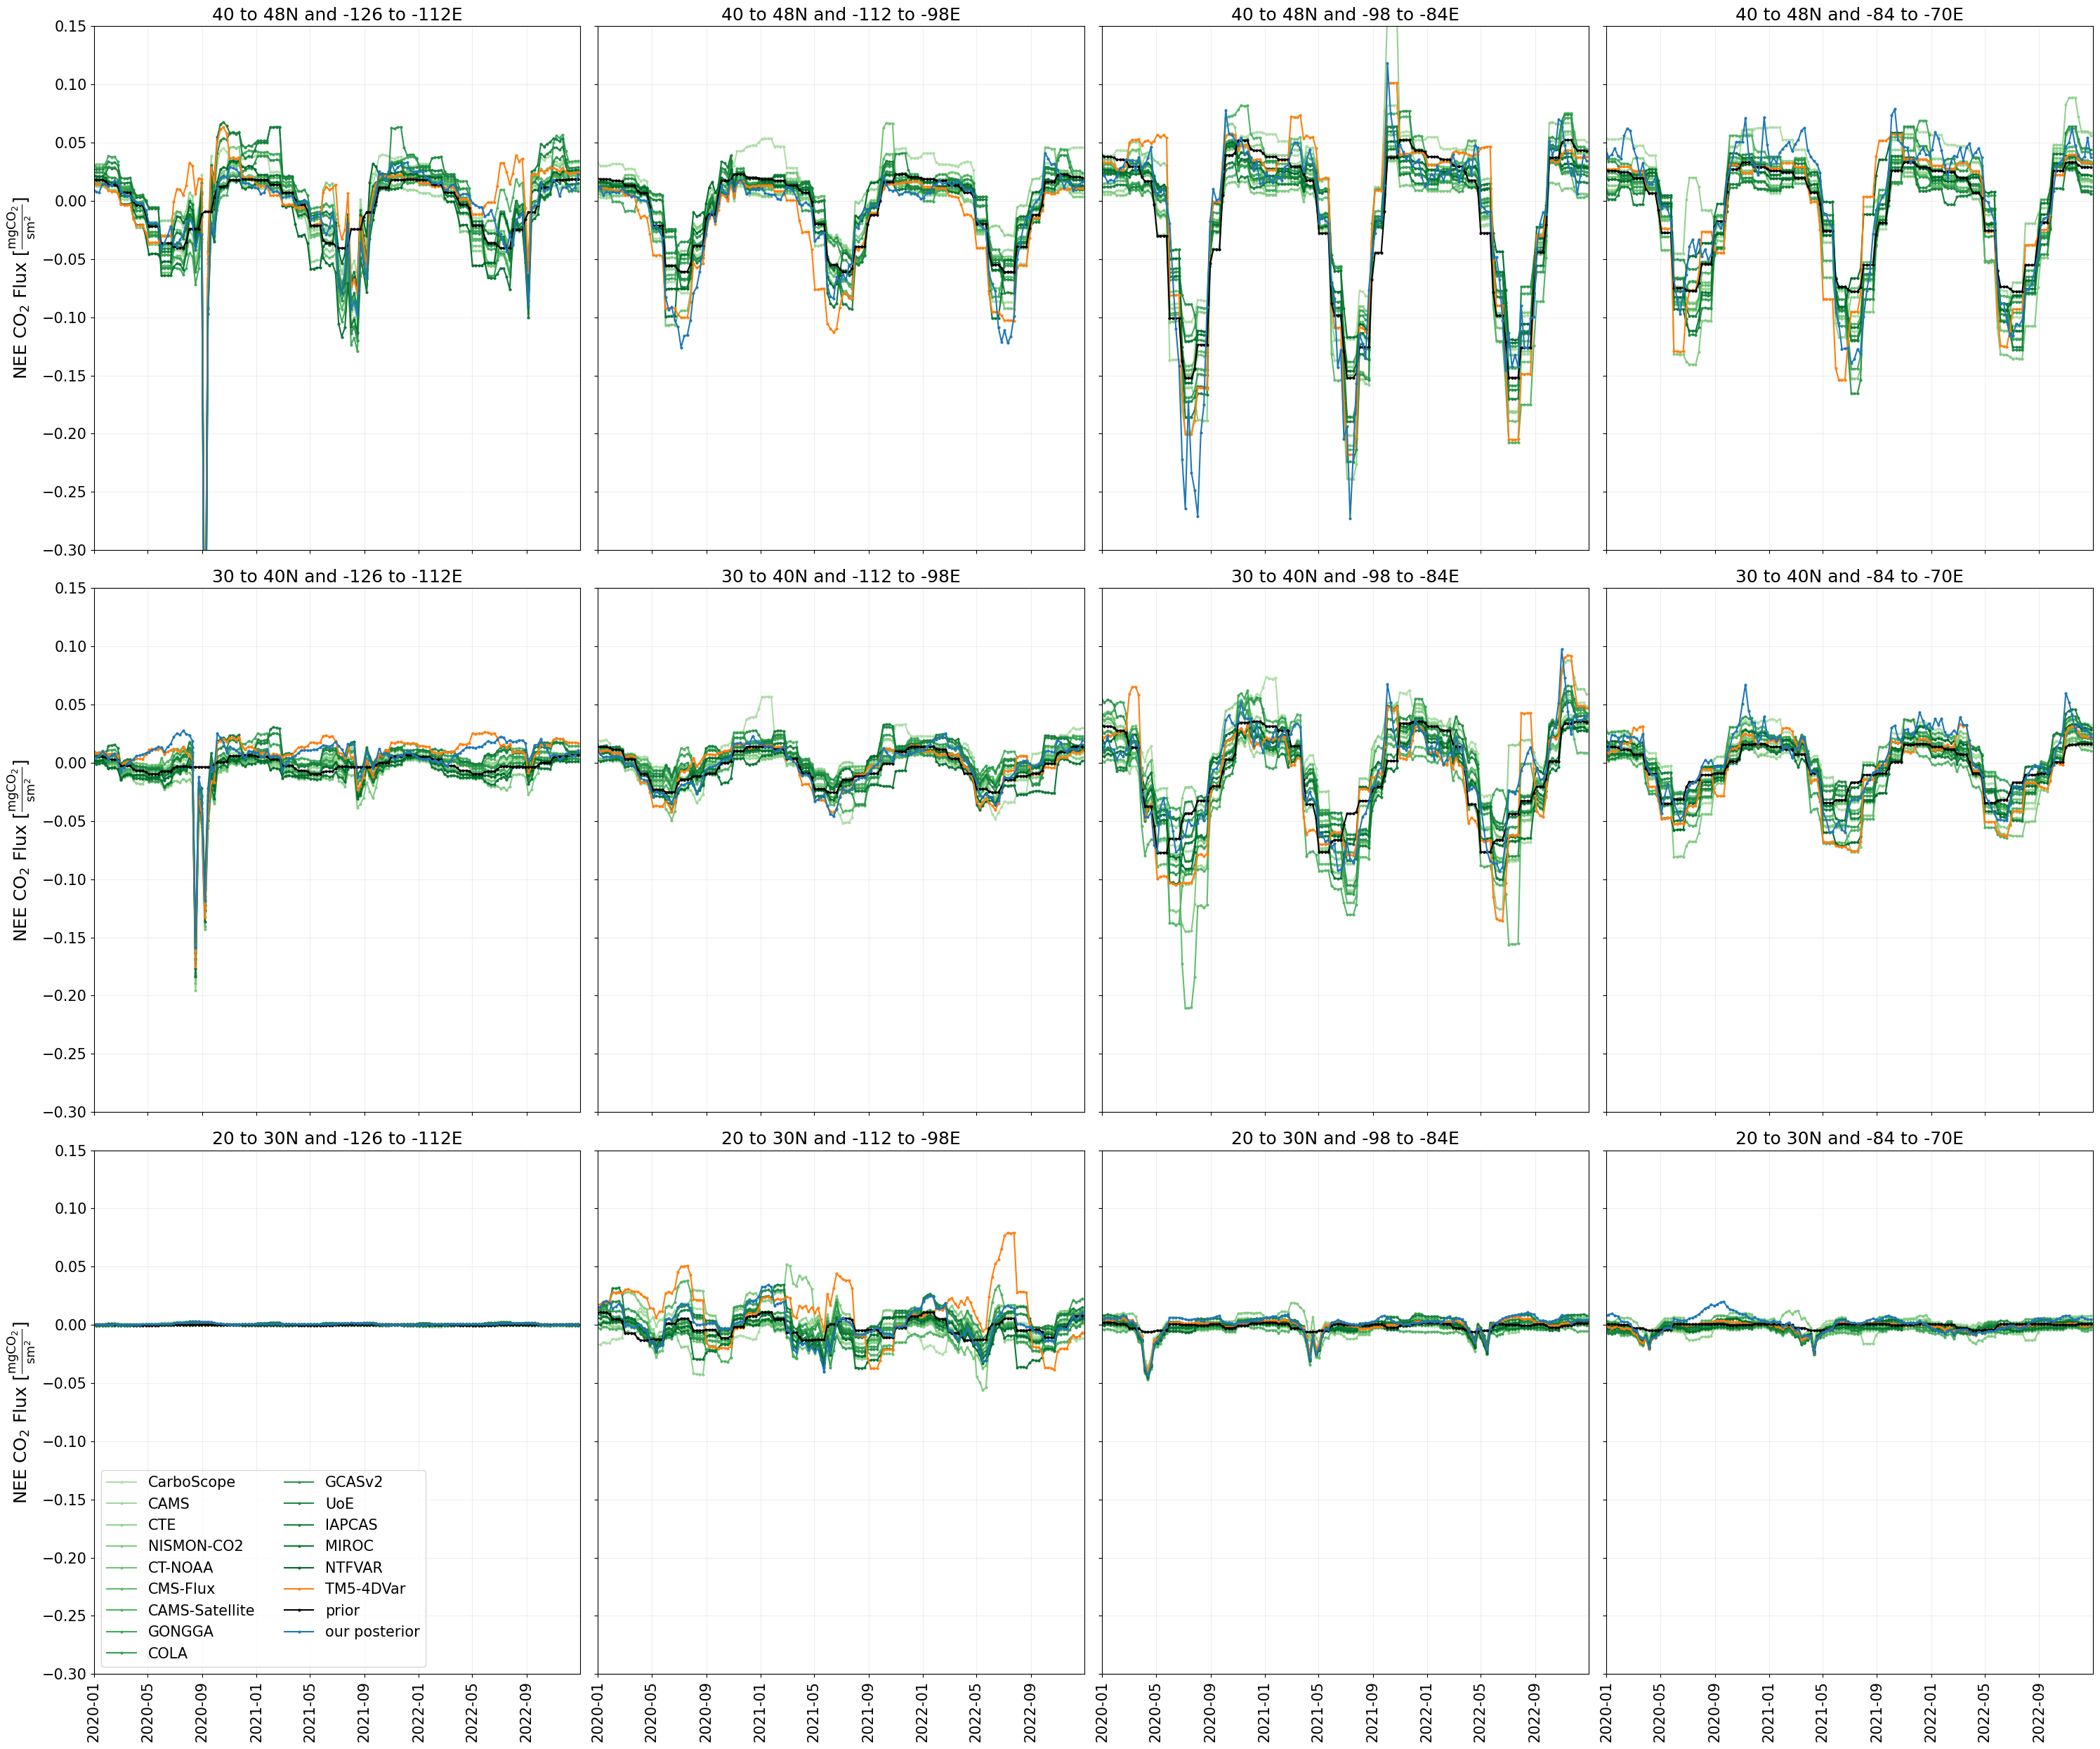

In [183]:
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(30,25))
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        for ensemble in (GCP.ensemble_member.values):
            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=(ensemble+8)/(len(GCP.ensemble_member)+10)
            axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])
        temp=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])    
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[1], markersize=2,label='TM5-4DVar')
        
        temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color='black', markersize=2,label='prior')

        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[0], markersize=2,label='our posterior')
        if j==0:
            axs[i,j].set_ylabel('NEE CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)
            axs[i,j].tick_params(labelsize =15)
        else:
            axs[i,j].tick_params(labelleft=False)
        axs[i,j].set_ylim(-0.3,0.15)
        axs[i,j].set_xlim(analysis_start_date,analysis_end_date)
        if (i==2)&(j==0):
            axs[i,j].legend(ncol=2,loc='lower left',fontsize=15)
        if i==2:
            axs[i,j].tick_params(axis='x', labelrotation=90,labelsize =15)
            #axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)  
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)                 
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E", fontsize=18)
        
plt.tight_layout()
plt.savefig(f'{savefig}/NEE_flux_regional_timeline.pdf',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()

In [41]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
    for j in range(n_regions[1]): #lon
        temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')
        temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[1], markersize=2,label='prior')
        #axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

        temp=TM54DVar_posterior_flux
        temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        color=0.9
        axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label='TM5-4DVar')

        axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
        axs[i,j].set_ylim(-0.2,0.15)
        axs[i,j].legend()
        axs[i,j].tick_params(axis='x', labelrotation=45)

        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
            
plt.tight_layout()
plt.savefig(f'{savefig}/ensembles/NEE_flux_regional_timeline_TM54DVar.png',bbox_inches='tight')#,transparent=True)
#plt.show()
plt.close()

In [42]:
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
for ensemble in (GCP.ensemble_member.values):
    fig,axs=plt.subplots(n_regions[0],n_regions[1],figsize=(40,20))
    for i in range(n_regions[0]): #lat(0.02, plt.cm.Reds(0.60)),
        for j in range(n_regions[1]): #lon
            temp=inversion.fluxes.where(((inversion.fluxes.latitude>= regions_lat[-i-2]) &(inversion.fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[0], markersize=2,label='our model posterior')

            temp=prior.where(((prior.latitude>= regions_lat[-i-2]) &(prior.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color=default_colors[1], markersize=2,label='prior')
            #axs[i,j].fill_between(temp.time, temp.TM5_prior_flux*1e6-temp.prior_uncertainty*1e6, temp.TM5_prior_flux*1e6+temp.prior_uncertainty*1e6, color='black', alpha=0.2) 

            temp=GCP.sel(ensemble_member=ensemble)
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            color=0.9
            axs[i,j].plot(temp.time, temp.CO2_flux_nee*1e6, marker='o', color= plt.cm.Greens(color), markersize=2,label=gcp_names[ensemble])

            axs[i,j].set_ylabel('total co2 flux [[$\\mathrm{\\frac{mgCO_2}{s m^2}}$]]')
            axs[i,j].set_ylim(-0.2,0.15)
            axs[i,j].legend()
            axs[i,j].tick_params(axis='x', labelrotation=45)

            axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
                
    plt.tight_layout()
    plt.savefig(f'{savefig}/ensembles/NEE_flux_regional_timeline_{gcp_names[ensemble]}.png',bbox_inches='tight')#,transparent=True)
    #plt.show()
    plt.close()